# 02 Leave-one-device-out (LODO)

Each unit trains on three ICBHI devices and is tested on all recordings of the held-out device. Seeds: 5 for the anchor and
target arms, 3 (0-2) for the distilled students. Figures: `outputs/figures/lodo/`.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/common.py
sys.path.insert(0, str(Path.cwd().parent))   # repository root for src.*
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from common import *
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
FIG, TAB = out_dirs('lodo')
rows = []
for a in ARMS:
    for dv in LODO:
        for s in range(5):
            if exists(a, dv, s):
                t = report(a, dv, s)['last']['test']['all']
                rows.append(dict(arm=a, device=LODO_NAME[dv], seed=s, score=t['score'], sp=t['sp'], se=t['se']))
for dv in LODO:
    for s in range(5):
        if all(exists(a, dv, s) for a in G4):
            p, y, _, _ = ensemble(G4, dv, s); sp, se, sc = icbhi_score(p, y)
            rows.append(dict(arm='G4 ensemble', device=LODO_NAME[dv], seed=s, score=sc, sp=sp, se=se))
L = pd.DataFrame(rows); L.to_csv(TAB / 'lodo_per_seed.csv', index=False)
print(L.groupby('arm').seed.nunique())

arm
G4 ensemble          5
anchor               5
class_aware_light    5
kd_g4_k1             3
kd_g4_k2             3
lora                 5
lora_class_aware     5
multiscale           5
pcsl5_control        5
swa                  5
Name: seed, dtype: int64


## 1. Score per held-out device and macro mean

Macro = mean over the four devices for each seed; compared on the seeds every arm has (0-2) and on all seeds.

In [2]:
tab = L.groupby(['arm', 'device']).score.mean().unstack()
macro = L.groupby(['arm', 'seed']).score.mean().groupby('arm').agg(['mean', 'std', 'size'])
common = L[L.seed <= 2].groupby(['arm', 'seed']).score.mean().groupby('arm').mean().rename('macro_seeds_0_2')
tab = tab.join(macro.rename(columns={'mean': 'macro_all_seeds', 'std': 'macro_sd', 'size': 'seeds'})).join(common).sort_values('macro_seeds_0_2', ascending=False)
tab.to_csv(TAB / 'lodo_summary.csv'); tab

,AKGC417L,Litt3200,LittC2SE,Meditron,macro_all_seeds,macro_sd,seeds,macro_seeds_0_2
arm,,,,,,,,
G4 ensemble,55.64,64.38,68.23,60.64,62.22,1.21,5,62.26
kd_g4_k2,54.29,61.70,69.56,61.51,61.77,2.62,3,61.77
kd_g4_k1,54.63,61.15,70.58,60.55,61.72,2.50,3,61.72
multiscale,55.30,64.12,66.87,59.33,61.41,1.45,5,61.68
swa,55.28,62.48,68.51,60.81,61.77,1.36,5,61.32
anchor,55.41,63.57,67.19,60.30,61.62,1.45,5,61.22
pcsl5_control,56.28,59.64,67.89,59.09,60.72,1.66,5,60.93
class_aware_light,54.11,57.92,69.95,58.29,60.07,1.86,5,60.22
lora,53.46,53.81,67.96,55.99,57.81,1.18,5,58.37


PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/lodo/lodo_heatmap_macro.png')

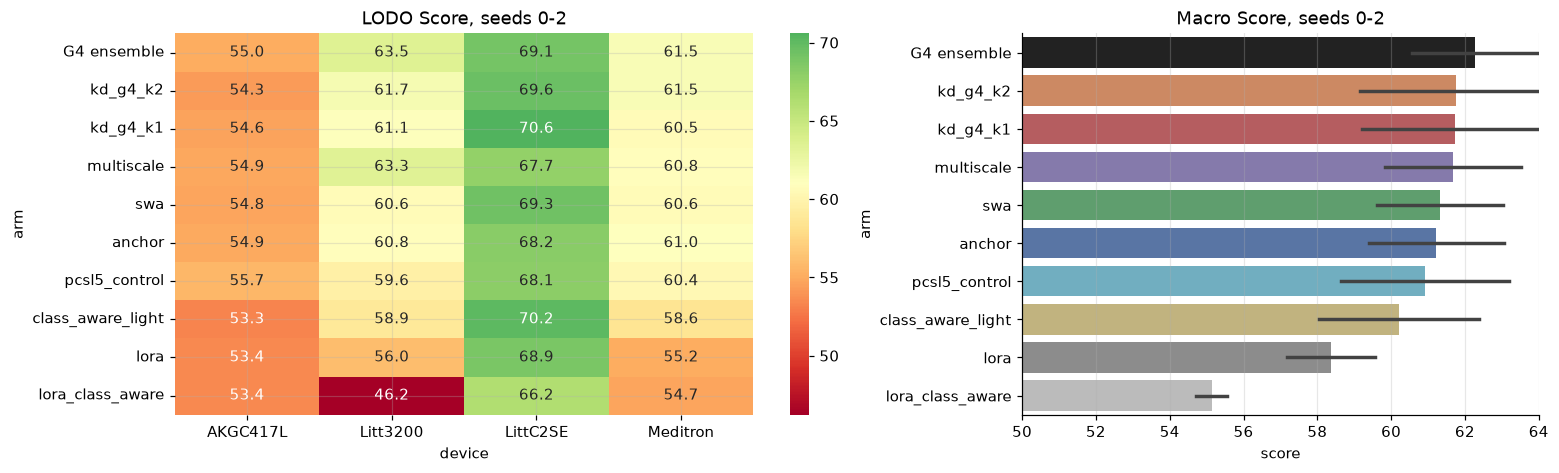

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.4, 1]})
sub = L[L.seed <= 2]
order = tab.index.tolist()
sns.heatmap(sub.groupby(['arm', 'device']).score.mean().unstack().loc[order], annot=True, fmt='.1f', cmap='RdYlGn', center=61, ax=ax[0])
ax[0].set_title('LODO Score, seeds 0-2')
m = sub.groupby(['arm', 'seed']).score.mean().reset_index()
sns.barplot(data=m, y='arm', x='score', order=order, palette=[PALETTE.get(a, '#999') for a in order], errorbar='sd', ax=ax[1])
ax[1].set_xlim(50, 64); ax[1].set_title('Macro Score, seeds 0-2')
savefig(fig, FIG, 'lodo_heatmap_macro')

## 2. Paired change to the anchor per device (seeds 0-2)

device,AKGC417L,Litt3200,LittC2SE,Meditron
arm,,,,
G4 ensemble,0.13,2.62,0.91,0.48
kd_g4_k1,-0.29,0.30,2.42,-0.43
kd_g4_k2,-0.62,0.85,1.41,0.53
multiscale,-0.05,2.48,-0.48,-0.14
swa,-0.16,-0.21,1.16,-0.40


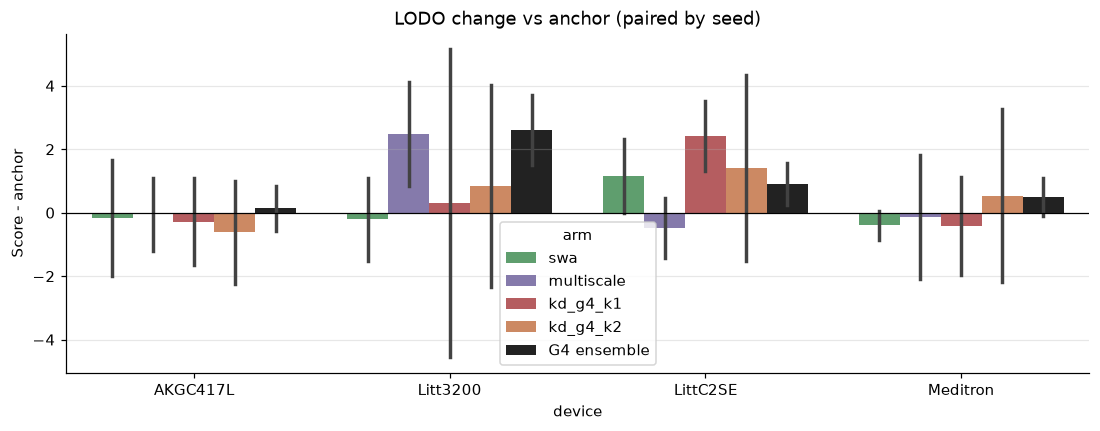

In [4]:
base = sub[sub.arm == 'anchor'].set_index(['device', 'seed']).score
dd = sub[sub.arm.isin(['kd_g4_k1', 'kd_g4_k2', 'G4 ensemble', 'swa', 'multiscale'])].copy()
dd['delta'] = dd.score - dd.set_index(['device', 'seed']).index.map(base)
fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(data=dd, x='device', y='delta', hue='arm', palette=PALETTE, errorbar='sd', ax=ax)
ax.axhline(0, color='k', lw=0.8); ax.set_ylabel('Score - anchor'); ax.set_title('LODO change vs anchor (paired by seed)')
savefig(fig, FIG, 'lodo_delta_vs_anchor')
dd.groupby(['arm', 'device']).delta.mean().unstack().round(2)

## 3. Sensitivity and specificity trade-off per held-out device

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/lodo/lodo_sp_se.png')

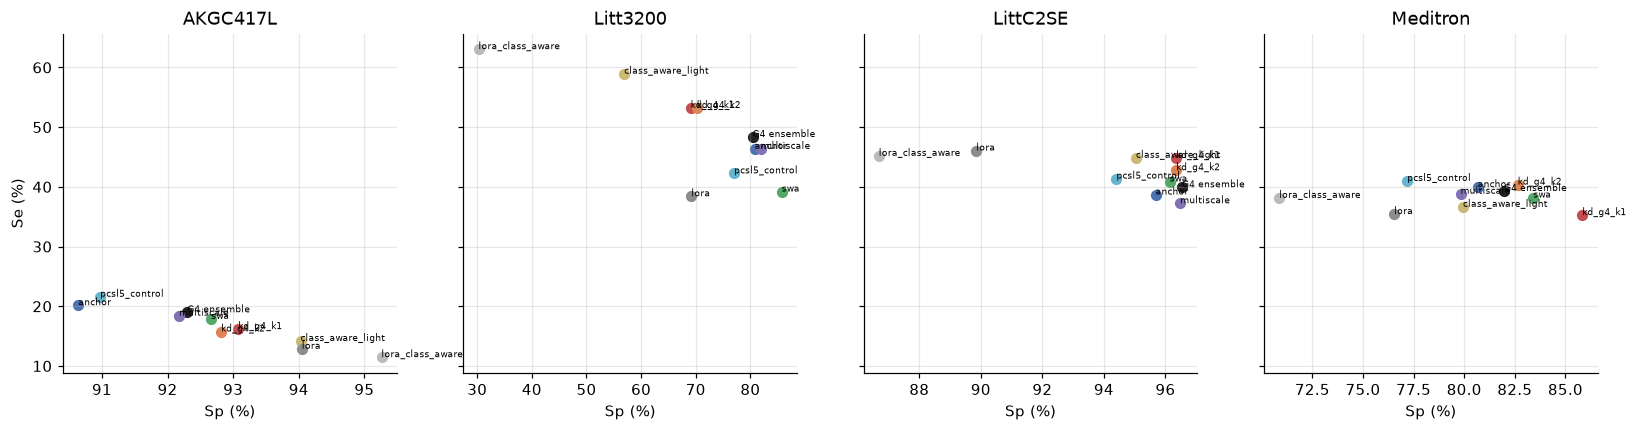

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for i, dv in enumerate(['AKGC417L', 'Litt3200', 'LittC2SE', 'Meditron']):
    g = L[L.device == dv].groupby('arm')[['sp', 'se']].mean()
    for a, r in g.iterrows():
        ax[i].scatter(r.sp, r.se, color=PALETTE.get(a, '#999'), s=40); ax[i].annotate(a, (r.sp, r.se), fontsize=6)
    ax[i].set_title(dv); ax[i].set_xlabel('Sp (%)')
ax[0].set_ylabel('Se (%)')
savefig(fig, FIG, 'lodo_sp_se')

## 4. Test Score over epochs on the held-out device (anchor vs distilled K1)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/lodo/lodo_curves.png')

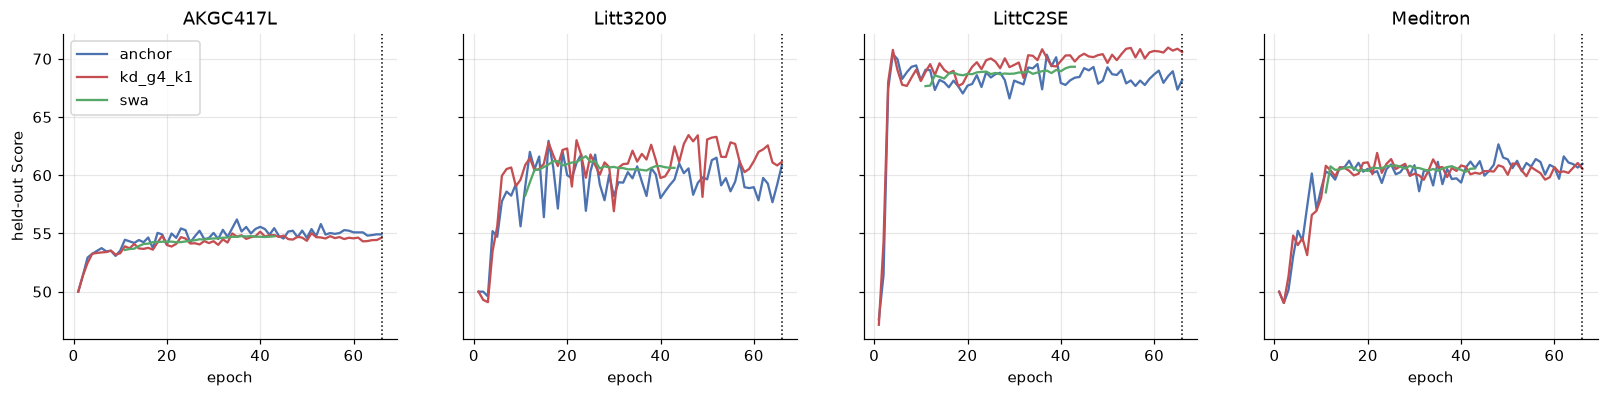

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for i, dv in enumerate(LODO):
    for a in ['anchor', 'kd_g4_k1', 'swa']:
        hs = [history(a, dv, s) for s in range(3) if exists(a, dv, s)]
        if not hs: continue
        m = pd.concat(hs).groupby('epoch').test_score.mean(); ax[i].plot(m.index, m, label=a, color=PALETTE.get(a))
    ax[i].axvline(66, color='k', ls=':', lw=1); ax[i].set_title(LODO_NAME[dv]); ax[i].set_xlabel('epoch')
ax[0].legend(); ax[0].set_ylabel('held-out Score')
savefig(fig, FIG, 'lodo_curves')

## 5. Held-out class mix and confusion of the distilled student

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/lodo/lodo_confusion_kd_g4_k1.png')

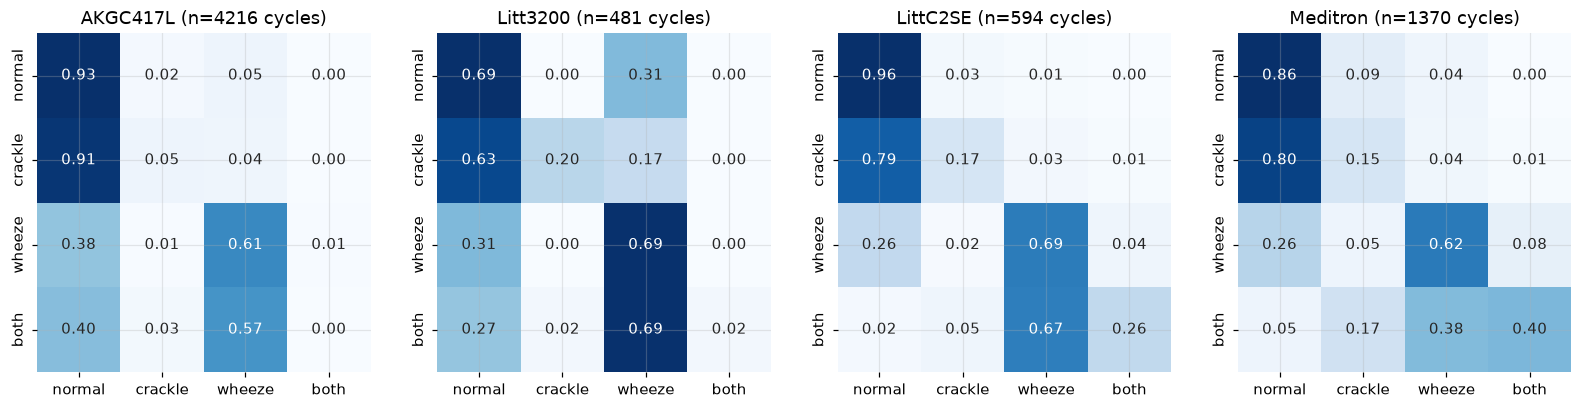

In [7]:
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, dv in enumerate(LODO):
    cm = sum(confusion_matrix(preds('kd_g4_k1', dv, s)[1], preds('kd_g4_k1', dv, s)[0].argmax(1), labels=range(4)) for s in range(3))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[i])
    ax[i].set_title(f'{LODO_NAME[dv]} (n={cm.sum() // 3} cycles)')
savefig(fig, FIG, 'lodo_confusion_kd_g4_k1')

## Notes

- [Fact] The distilled K1 student keeps about half of the G4 ensemble's LODO macro gain over the anchor; seeds 0 and 2 are
  slightly negative, seed 1 strongly positive.
- [Fact] AKGC417L is the hardest held-out device (class-mix dominated: most crackle cycles are on this device).
- [Interpretation] Device shift effects are mixed with class-mix shift; a LODO Score change is not a pure device effect.